# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

I0000 00:00:1793600963.709499     515 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793600963.771271     515 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793600965.791253     515 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

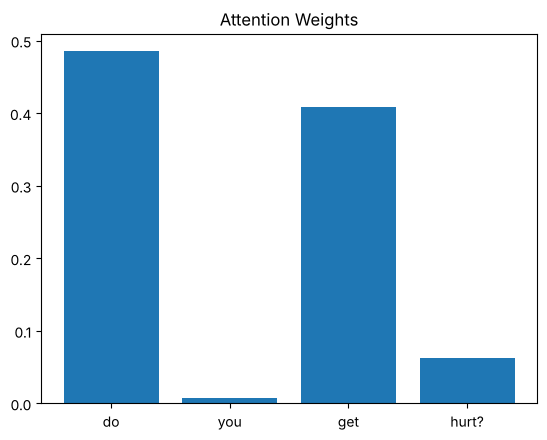

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [7]:
# Helper function: get the attention weights of one question and plot them
# The words are taken from the tokenizer (the same words the model receives), so punctuation is removed.
answers = df.drop_duplicates("answer_id").set_index("answer_id")["answer"]

def show_attention(index):
    question = df["question"][index]
    tokens = [tokenizer.index_word[i] for i in X[index].tolist() if i != 0]   # ignore padding (0)

    with torch.no_grad():
        prediction, weights = model(X[index:index + 1])

    word_weights = weights[0, :len(tokens)].tolist()
    top_word = tokens[word_weights.index(max(word_weights))]

    plt.figure(figsize=(7, 3))
    plt.bar(tokens, word_weights)
    plt.title(f'Attention Weights: "{question}"')
    plt.ylabel("Weight")
    plt.show()

    print(f"Question: {question}")
    print(f"Correct answer:   {df['answer'][index]}")
    print(f"Predicted answer: {answers[prediction.argmax(1).item()]}")
    print(f"Word with the highest attention: '{top_word}' ({max(word_weights):.2f})\n")
    return top_word

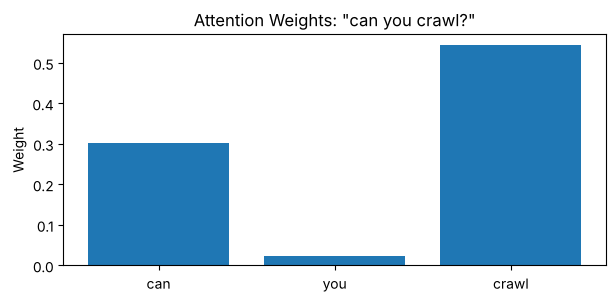

Question: can you crawl?
Correct answer:   I don't have a body.
Predicted answer: I don't have a body.
Word with the highest attention: 'crawl' (0.54)



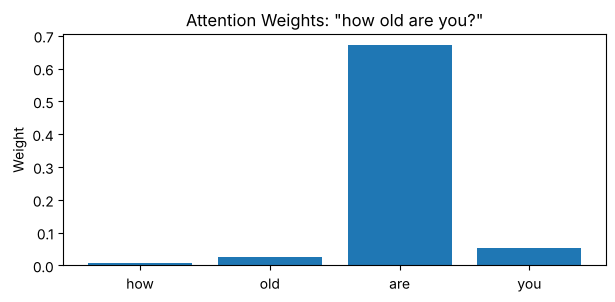

Question: how old are you?
Correct answer:   Age doesn't really apply to me.
Predicted answer: People created me.
Word with the highest attention: 'are' (0.67)



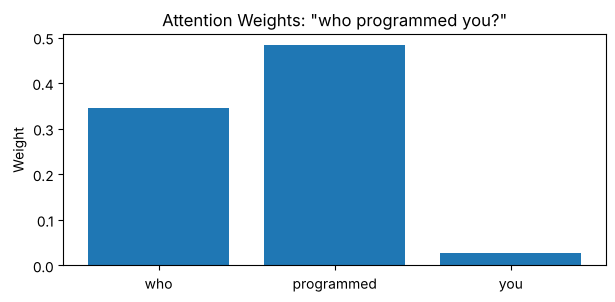

Question: who programmed you?
Correct answer:   People created me.
Predicted answer: People created me.
Word with the highest attention: 'programmed' (0.48)



In [8]:
# Task 1: three different questions from the dataset
selected = [6, 24, 42]

for index in selected:
    show_attention(index)

**Answer — Task 1**

| Question | Word with the highest attention |
|---|---|
| Can you crawl? | **crawl** |
| How old are you? | **are** |
| Who programmed you? | **programmed** |

Partly. In *"Can you crawl?"* and *"Who programmed you?"* the model focuses on **crawl** and **programmed**, which are the key words that tell us what the question is about (a body action and who made the chatbot). In *"How old are you?"*, however, most of the attention goes to **are**, while the important word **old** gets almost no weight, and the model predicts the wrong answer for this question.

This shows that attention weights do not always match what a human thinks is important. The model is small, it was trained for only 50 epochs on 168 questions, and its training accuracy is low, so it sometimes relies on common words (*do*, *are*) instead of the meaningful ones. A better-trained model would usually give more weight to the content words.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

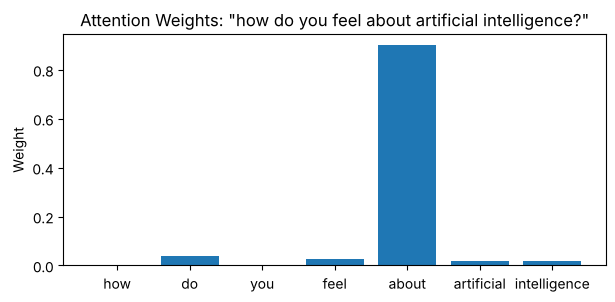

Question: how do you feel about artificial intelligence?
Correct answer:   The world of technology is fascinating.
Predicted answer: I'm better at answering questions.
Word with the highest attention: 'about' (0.90)



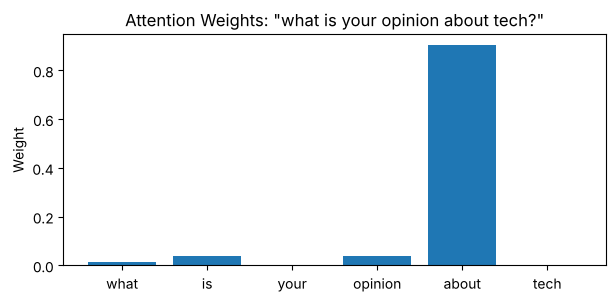

Question: what is your opinion about tech?
Correct answer:   The world of technology is fascinating.
Predicted answer: I'm better at answering questions.
Word with the highest attention: 'about' (0.90)

Highest attention in question 1: 'about'
Highest attention in question 2: 'about'


In [9]:
# Task 2: two questions with a similar meaning but different wording (both have the same answer)
q1, q2 = 126, 132

top1 = show_attention(q1)
top2 = show_attention(q2)

print(f"Highest attention in question 1: '{top1}'")
print(f"Highest attention in question 2: '{top2}'")

**Answer — Task 2**

The two questions *"How do you feel about artificial intelligence?"* and *"What is your opinion about tech?"* ask the same thing in different words. In both of them, the model gives almost all of its attention (about 0.90) to the same word, **about**, and it gives the same prediction for both questions. However, this prediction is not the correct answer.

So the model focuses on **similar** words when the questions are built in a similar way. This suggests that attention is learned from the training data: the model gives high weights to the words it has found useful for its decision, and similar questions get similar attention patterns. But the important words here are *artificial intelligence* and *tech*, and they get almost no weight. This shows that attention does not always point to the words a human would choose. Because this small model is not well trained, its attention picked up a common word (*about*) instead of the key topic words, which is also why it chose the wrong answer.